# Plot mouse-to-mouse varability (SFig 5)

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")

import clones

import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)



from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5



def get_bootstrap_ci(bootstrap_samples, axis=0, confidence=0.95):
    """
    Calculate confidence intervals from bootstrap samples along a specified axis.
    
    Parameters:
    -----------
    bootstrap_samples : array-like
        3D array of bootstrap samples where:
        - First dimension is the number of bootstrap samples
        - Second and third dimensions are your original 2D data shape
    axis : int, default=0
        The axis of the original 2D data along which to calculate CIs
        0 = calculate CI for each column
        1 = calculate CI for each row
    confidence : float, default=0.95
        Confidence level (0 to 1)
        
    Returns:
    --------
    tuple
        (lower_bounds, upper_bounds, means)
        Each is an array corresponding to the CIs and means along the specified axis
    """
    # Convert input to numpy array if it isn't already
    samples = np.asarray(bootstrap_samples)
    
    # Calculate alpha for confidence interval
    alpha = (1 - confidence) / 2
    
    # Calculate percentiles and mean along the bootstrap samples dimension
    # Add 1 to axis because original axis 0/1 is now 1/2 due to bootstrap dimension
    lower_bounds = np.nanpercentile(samples, alpha * 100, axis=0)
    upper_bounds = np.nanpercentile(samples, (1 - alpha) * 100, axis=0)
    means = np.mean(samples, axis=0)
    
    # If axis=0 (columns), we want stats for each column of original data
    # If axis=1 (rows), we want stats for each row of original data
    if axis == 0:
        return lower_bounds, upper_bounds, means
    elif axis == 1:
        return (lower_bounds.T, upper_bounds.T, means.T)
    else:
        raise ValueError("Axis must be 0 or 1")

    

In [7]:
#Load clonal data

exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']

exp_data_F = load_object(exp_folder + 'data_ctr_F.pkl')
livesize_F = exp_data['livesize']

exp_data_M = load_object(exp_folder + 'data_ctr_M.pkl')
livesize_M = exp_data['livesize']

colm = {'M30': 'r', 'M1': 'b', 'M14': 'g', 'M3': 'tab:orange', 'M1bis': 'tab:purple',
        'F3':  'r', 'F4': 'b', 'F11': 'g', 'F9': 'tab:orange', 'F10': 'tab:purple'}
fmice = ['F3', 'F4', 'F11', 'F9', 'F10']
mmice = ['M30', 'M1', 'M14', 'M3', 'M1bis']
sex = ['F', 'M']


save_folder = 'Figures/SFig5/'

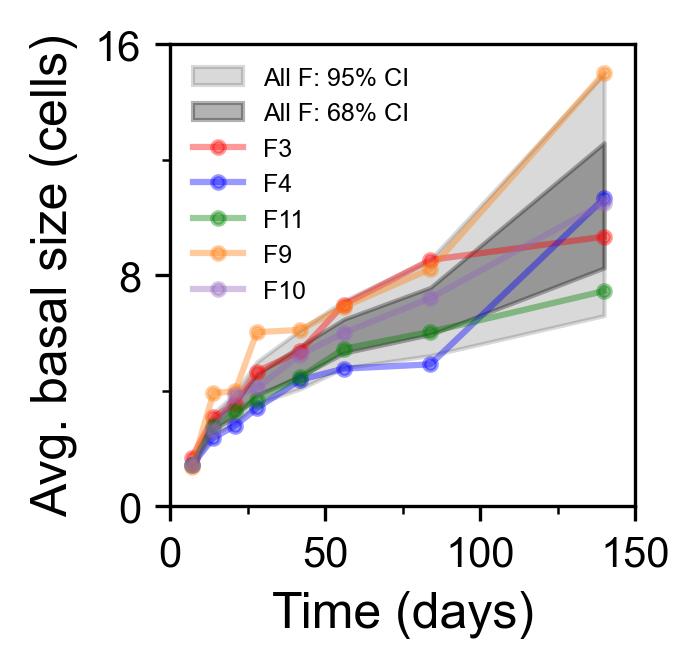

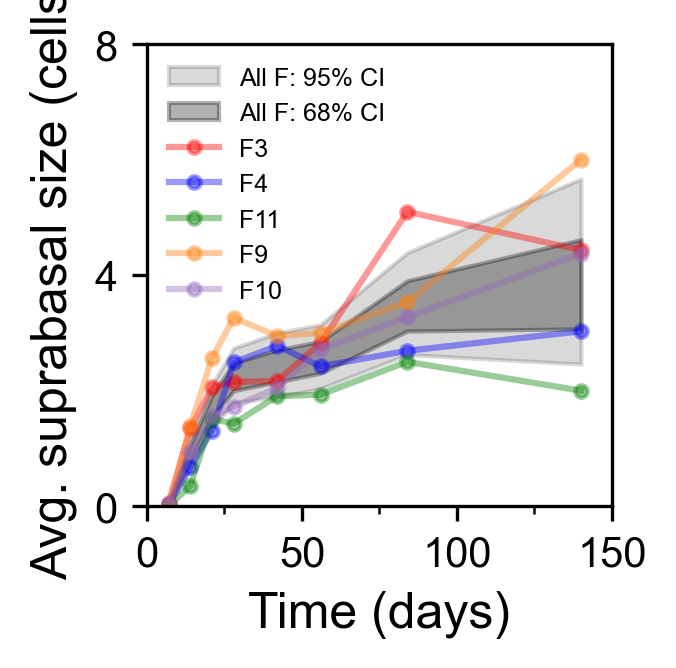

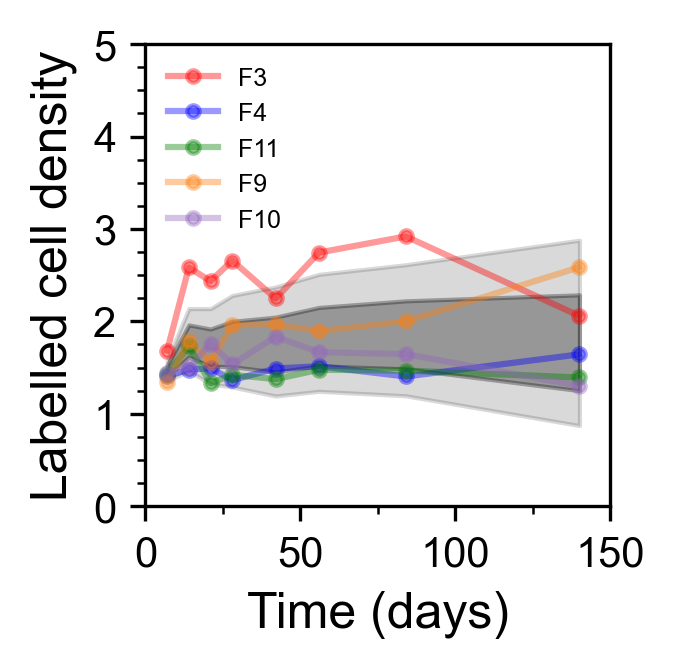

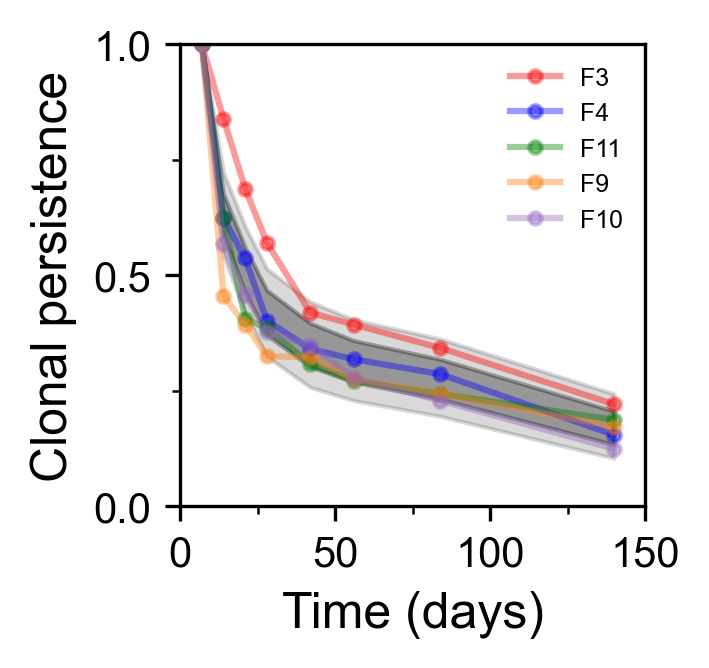

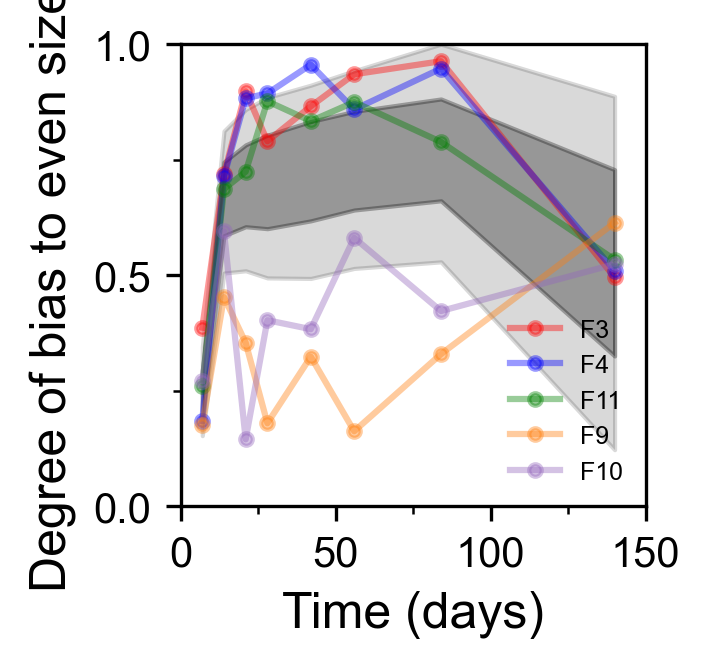

In [8]:
'''
    Show that mouse-by-mouse dynamics fall within subsampled dynamics by sex
'''


nboots = 5000
a1 = 15

sex = 'F'
plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']

clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All F')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3, label = f'All {sex}: 68% CI')
for mid in fmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.plot(clone_anal.tvals, clone_anal.av_bas_cs, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Avg. basal size (cells)')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,16])
plt.yticks(np.arange(0,17,8))
plt.yticks(np.arange(0,17,4), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'basal_size_F.pdf')
plt.show()


plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']

clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All F')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('av_sup_cs', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3, label = f'All {sex}: 68% CI')
for mid in fmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.plot(clone_anal.tvals, clone_anal.av_sup_cs, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Avg. suprabasal size (cells)')
plt.legend(frameon = False, loc = 'upper left', fontsize = 6)
plt.ylim([0,8])
plt.yticks(np.arange(0,9,4))
#plt.yticks(np.arange(0,25,2), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'supra_size_F.pdf')
plt.show()



plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All F')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('lcd', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15)#, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3)#, label = f'All {sex}: 68% CI')
for mid in fmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])#, subpop = 'S4like')
    #clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
    plt.plot(clone_anal.tvals, clone_anal.lcd, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')
#plt.ylabel('S labelled cell density')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,5])
plt.yticks(np.arange(0,5.1,1))
plt.yticks(np.arange(0,5,0.25), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'labelled_density_F.pdf')
plt.show()



plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All F')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('pers', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15)#, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3)#, label = f'All {sex}: 68% CI')
for mid in fmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])#, subpop = 'S4like')
    #clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
    plt.plot(clone_anal.tvals, clone_anal.pers, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Clonal persistence')
#plt.ylabel('S labelled cell density')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,1])
plt.yticks(np.arange(0,1.1,0.5))
plt.yticks(np.arange(0,1.1,0.25), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'F_persistence.pdf')
plt.show()



plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All F')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('ev_bas_cs', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15)#, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3)#, label = f'All {sex}: 68% CI')
for mid in fmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])#, subpop = 'S4like')
    #clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
    plt.plot(clone_anal.tvals, clone_anal.ev_bas_cs, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Degree of bias to even sizes')
#plt.ylabel('S labelled cell density')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,1])
plt.yticks(np.arange(0,1.1,0.5))
plt.yticks(np.arange(0,1.1,0.25), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'F_even_bias.pdf')
plt.show()




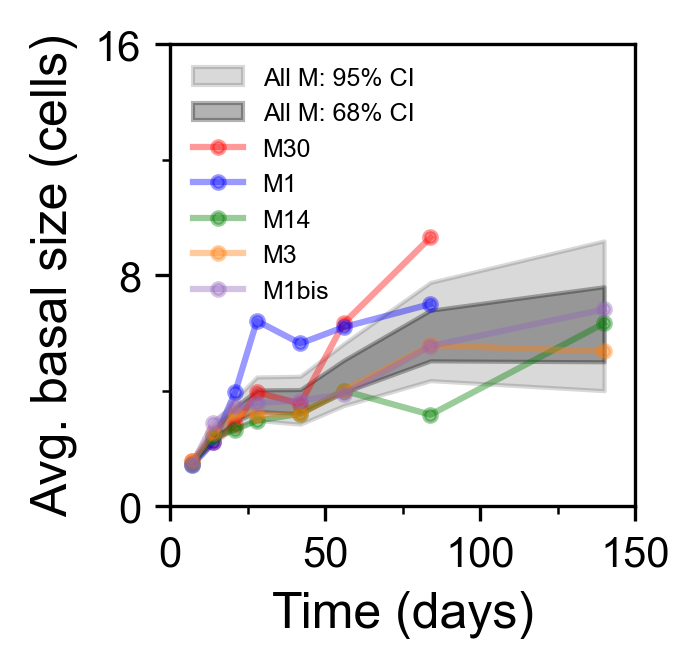

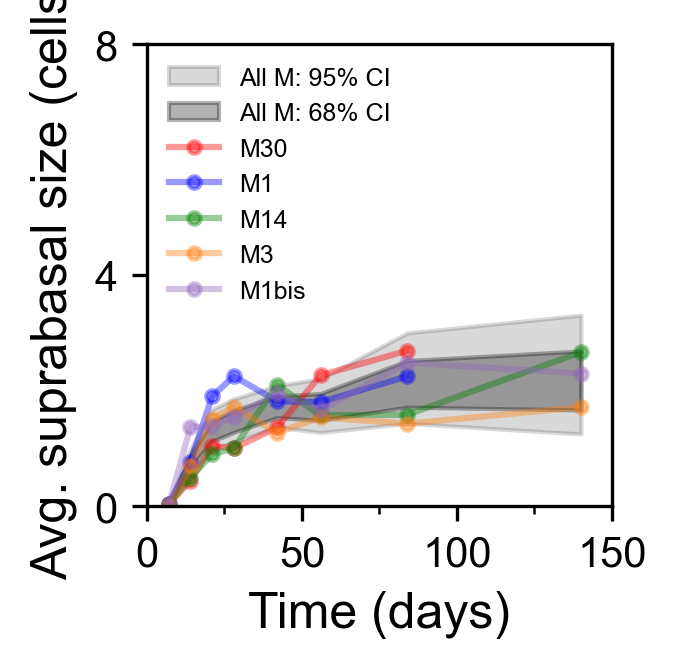

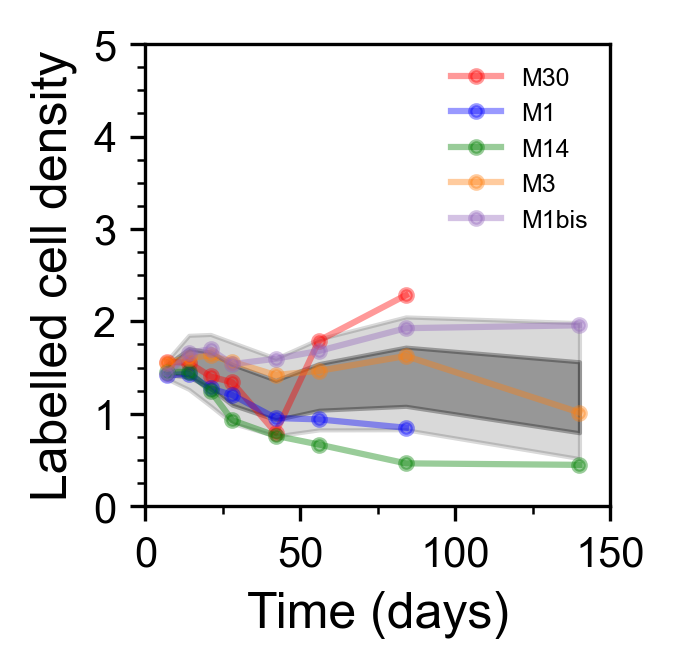

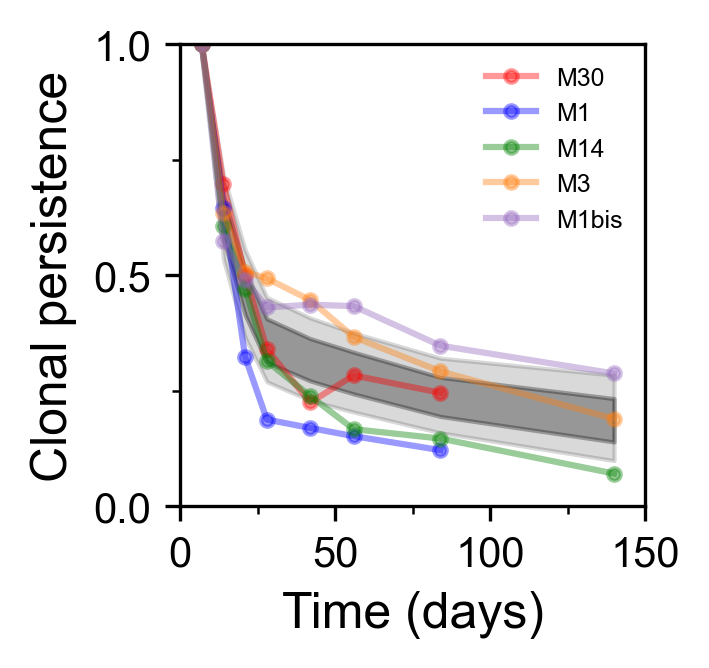

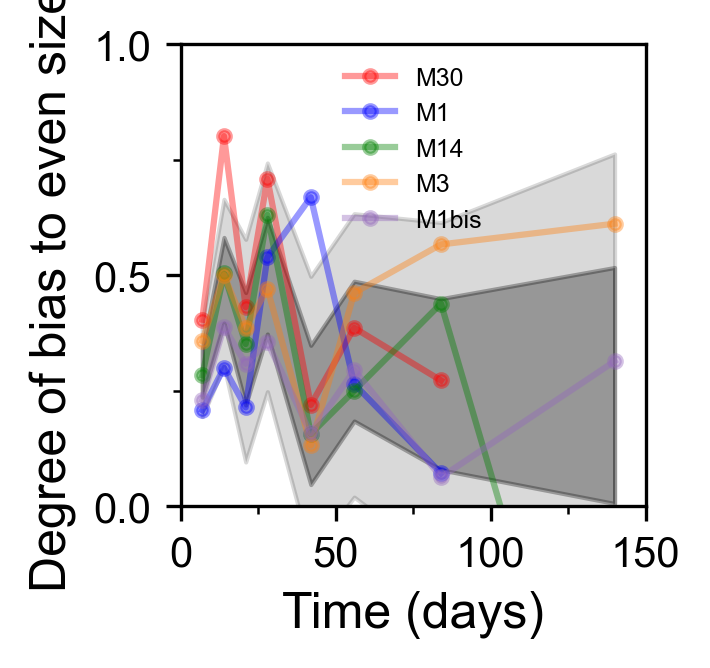

In [9]:
'''
    Show that mouse-by-mouse dynamics fall within subsampled dynamics by sex
'''


nboots = 5000
a1 = 15

sex = 'M'
plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']

clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All M')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3, label = f'All {sex}: 68% CI')
for mid in mmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.plot(clone_anal.tvals, clone_anal.av_bas_cs, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Avg. basal size (cells)')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,16])
plt.yticks(np.arange(0,17,8))
plt.yticks(np.arange(0,17,4), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'basal_size_M.pdf')
plt.show()


plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']

clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All M')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('av_sup_cs', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3, label = f'All {sex}: 68% CI')
for mid in mmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.plot(clone_anal.tvals, clone_anal.av_sup_cs, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Avg. suprabasal size (cells)')
plt.legend(frameon = False, loc = 'upper left', fontsize = 6)
plt.ylim([0,8])
plt.yticks(np.arange(0,9,4))
#plt.yticks(np.arange(0,25,2), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'supra_size_M.pdf')
plt.show()



plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All M')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('lcd', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15)#, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3)#, label = f'All {sex}: 68% CI')
for mid in mmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])#, subpop = 'S4like')
    #clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
    plt.plot(clone_anal.tvals, clone_anal.lcd, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Labelled cell density')
#plt.ylabel('S labelled cell density')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,5])
plt.yticks(np.arange(0,5.1,1))
plt.yticks(np.arange(0,5,0.25), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'labelled_density_M.pdf')
plt.show()



plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All M')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('pers', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15)#, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3)#, label = f'All {sex}: 68% CI')
for mid in mmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])#, subpop = 'S4like')
    #clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
    plt.plot(clone_anal.tvals, clone_anal.pers, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Clonal persistence')
#plt.ylabel('S labelled cell density')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,1])
plt.yticks(np.arange(0,1.1,0.5))
plt.yticks(np.arange(0,1.1,0.25), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'M_persistence.pdf')
plt.show()





plt.figure(figsize=(2,2), dpi = 300)
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr_' + sex + '.pkl')
livesize = exp_data['livesize']
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
#clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
#plt.plot(clone_anal.tvals*0, 0*clone_anal.av_bas_cs, 'k', label = 'All F')
#plt.plot(clone_anal.tvals, clone_anal.boot('av_bas_cs', nboots, None, sample_size = 109).T, 'o-',  color = 'k', alpha = a1/nboots, label = '_nolegend_')
db = clone_anal.boot('ev_bas_cs', nboots, None, sample_size = 109)
lower95, upper95, means95 = get_bootstrap_ci(db, 0, confidence = 0.95)
lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence = 0.68)
plt.fill_between(clone_anal.tvals, lower95, upper95, color = 'k', alpha = 0.15)#, label = f'All {sex}: 95% CI')
plt.fill_between(clone_anal.tvals, lower68, upper68, color = 'k', alpha = 0.3)#, label = f'All {sex}: 68% CI')
for mid in mmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])#, subpop = 'S4like')
    #clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'], subpop = 'S4like')
    plt.plot(clone_anal.tvals, clone_anal.ev_bas_cs, 'o-',  color = colm[mid], alpha = 0.4, label = mid)

plt.xlabel('Time (days)')
plt.ylabel('Degree of bias to even sizes')
#plt.ylabel('S labelled cell density')
plt.legend(frameon = False, fontsize = 6)
plt.ylim([0,1])
plt.yticks(np.arange(0,1.1,0.5))
plt.yticks(np.arange(0,1.1,0.25), minor = True)
plt.xlim([0, 150])
plt.xticks(np.arange(0,151,50))
plt.xticks(np.arange(0,151,25), minor = True)
plt.savefig(save_folder + 'M_even_bias.pdf')
plt.show()

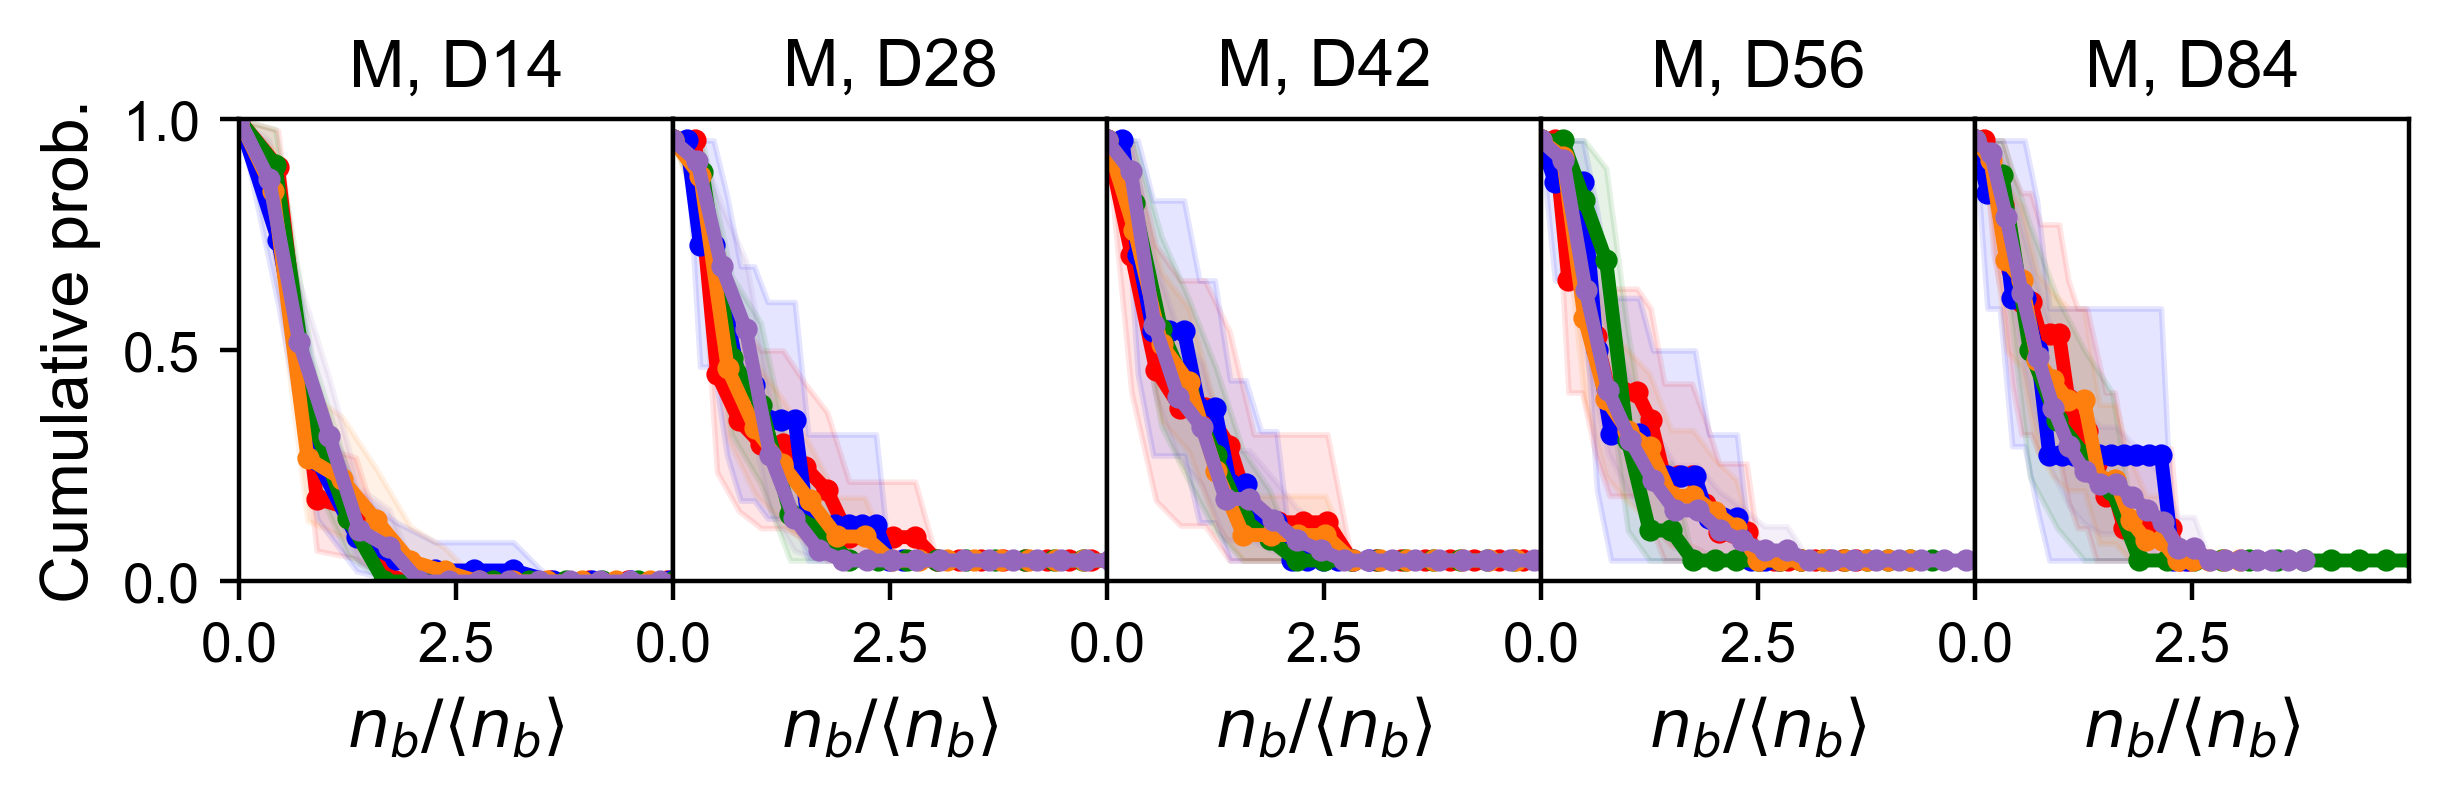

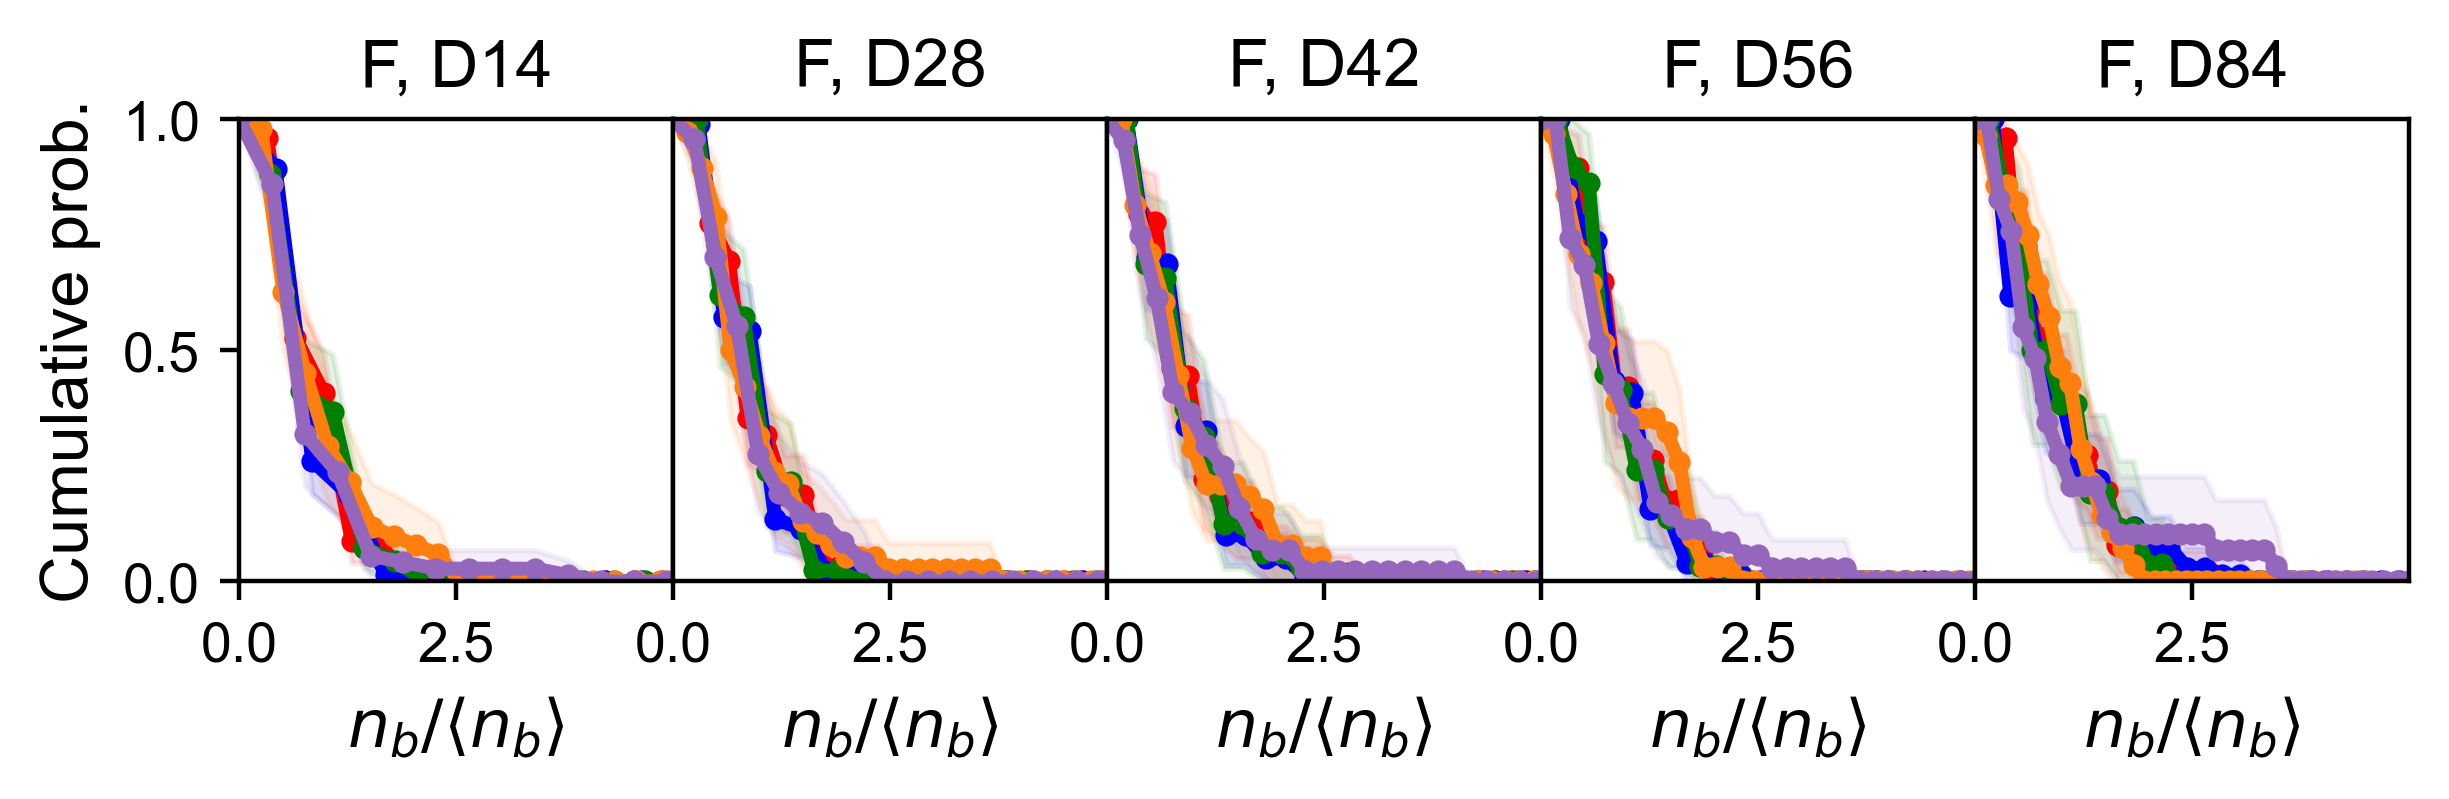

In [10]:
colm = {'M30': 'r', 'M1': 'b', 'M14': 'g', 'M3': 'tab:orange', 'M1bis': 'tab:purple',
        'F3':  'r', 'F4': 'b', 'F11': 'g', 'F9': 'tab:orange', 'F10': 'tab:purple'}

alpha = 1 - 0.95
fig, axs = plt.subplots(1, 5, figsize=(7, 1.5), dpi = 400)
xx = 0
times = list(exp_data['ctrTimeClonesize'])

subtimes = [1,3,4,5,6]

for mid in mmice[:]:
    exp_folder = '../../experiment/homeo/'
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    ccdf = clone_anal.bas_cdf()
    boot = clone_anal.bootpdf('bas_cdf', calc = None)
    l95 = np.quantile(boot, alpha/2, axis = 0)
    u95 = np.quantile(boot, 1 - alpha/2, axis = 0)

    for t in range(5):
        #xx = t // 4
        yy = t % 6
        tt = subtimes[t]
        axs[yy].plot(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], ccdf[tt,:].T, '-o', color = colm[mid], linewidth = 2.5, label = mid + f' ({clone_anal.nsur[t]})')
        axs[yy].fill_between(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], l95[tt,:], u95[tt,:], color = colm[mid], alpha = 0.1)
        #if mid == mmice[-1]:
        x = np.linspace(0, 5, 100)
        #axs[yy].plot(x, np.exp(-x), 'k-', label = r'$e^{-x}$')
        #    axs[yy].plot(x, np.exp(-x**2), 'k--', label = r'$e^{-x^2}$')
        #axs[yy].legend(loc = 'upper right')
        axs[yy].set_xlabel(r'$n_b/\langle n_b\rangle$')
        #axs[yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.15, linestyle = '--', label = '_nolegend_')
        #axs[yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.15, linestyle = '--', label = '_nolegend_')            
        axs[yy].set_xlim([0, 5])
        if t == 0:
            axs[yy].set_yticks([0, 0.5, 1.0])
            axs[yy].set_ylim([0, 1])
            axs[yy].set_ylabel('Cumulative prob.') 
        else:
            axs[yy].set_yticks([]) 

        if t == 5:
            axs[yy].set_xticks([0, 2.5, 5.0])
        else:
            axs[yy].set_xticks([0, 2.5])
        
        axs[yy].set_title(f'M, D{int(times[tt])}')
#plt.suptitle('Rescaled sizes, M, All clones', fontsize = 20)
plt.subplots_adjust(wspace=0, hspace=0)
plt.savefig(save_folder + 'rescaled_sizes_M.pdf')
plt.show()



alpha = 1 - 0.95
fig, axs = plt.subplots(1, 5, figsize=(7, 1.5), dpi = 400)
xx = 0
times = list(exp_data['ctrTimeClonesize'])

subtimes = [1,3,4,5,6]

for mid in fmice[:]:
    exp_folder = '../../experiment/homeo/'
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    ccdf = clone_anal.bas_cdf()
    boot = clone_anal.bootpdf('bas_cdf', calc = None)
    l95 = np.quantile(boot, alpha/2, axis = 0)
    u95 = np.quantile(boot, 1 - alpha/2, axis = 0)

    for t in range(5):
        #xx = t // 4
        yy = t % 6
        tt = subtimes[t]
        axs[yy].plot(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], ccdf[tt,:].T, '-o', color = colm[mid], linewidth = 2.5, label = mid + f' ({clone_anal.nsur[t]})')
        axs[yy].fill_between(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], l95[tt,:], u95[tt,:], color = colm[mid], alpha = 0.1)
        #if mid == mmice[-1]:
        x = np.linspace(0, 5, 100)
        #axs[yy].plot(x, np.exp(-(x-1/clone_anal.av_bas_cs[tt])), 'k-', label = r'$e^{-x}$')
        #    axs[yy].plot(x, np.exp(-x**2), 'k--', label = r'$e^{-x^2}$')
        #axs[yy].legend(loc = 'upper right')
        axs[yy].set_xlabel(r'$n_b/\langle n_b\rangle$')
        #axs[yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.15, linestyle = '--', label = '_nolegend_')
        #axs[yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.15, linestyle = '--', label = '_nolegend_')            
        axs[yy].set_xlim([0, 5])

        if t == 0:
            axs[yy].set_yticks([0, 0.5, 1.0])
            axs[yy].set_ylim([0, 1])
            axs[yy].set_ylabel('Cumulative prob.') 
        else:
            axs[yy].set_yticks([]) 

        if t == 5:
            axs[yy].set_xticks([0, 2.5, 5.0])
        else:
            axs[yy].set_xticks([0, 2.5])
                 
        #axs[yy].set_yticklabels(np.arange(0,1.1, 0.25), minor = True)
        axs[yy].set_ylim([0, 1])
        axs[yy].set_title(f'F, D{int(times[tt])}')
plt.subplots_adjust(wspace=0, hspace=0)
#plt.suptitle('Rescaled sizes, M, All clones', fontsize = 20)
#plt.tight_layout()
plt.savefig(save_folder + 'rescaled_sizes_F.pdf')
plt.show()

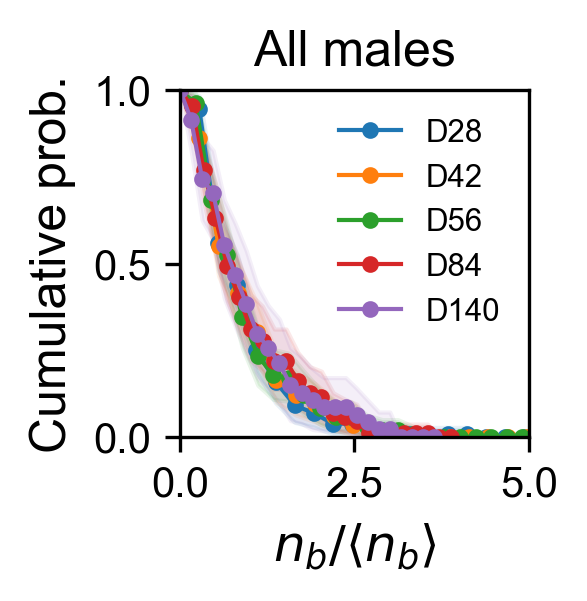

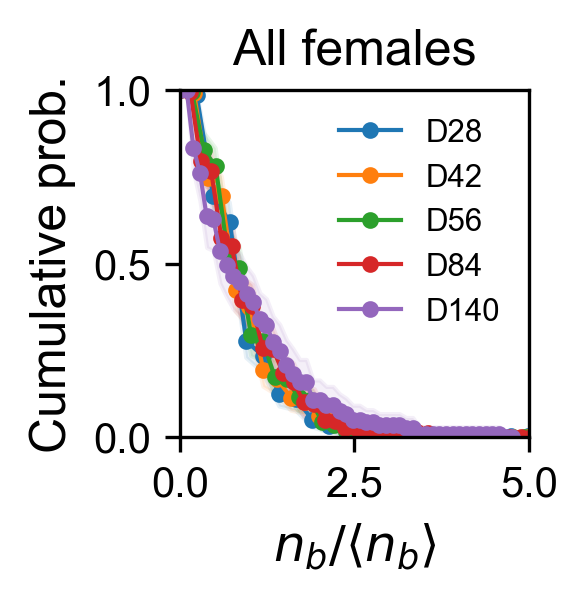

In [11]:
#subtimes = np.arange(3, 8)


colm['M'] = 'r'
colm['F'] = 'b'

colx = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2',
 '#7f7f7f', '#bcbd22', '#17becf']
names = {'M': 'male', 'F': 'female'}

subtimes = np.arange(3, 8)
for mid in ['M', 'F']:
    plt.figure(figsize=(1.5, 1.5), dpi = 300)
    exp_folder = '../../experiment/homeo/'
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    ccdf = clone_anal.bas_cdf()
    boot = clone_anal.bootpdf('bas_cdf', calc = None)
    l95 = np.quantile(boot, alpha/2, axis = 0)
    u95 = np.quantile(boot, 1 - alpha/2, axis = 0)

    for t in range(len(subtimes)):
        #xx = t // 4
        #yy = t % 6
        tt = subtimes[t]
        plt.plot(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], ccdf[tt,:].T, '-o', linewidth = 1, color = colx[t], label = mid + f' ({clone_anal.nsur[t]})')
        plt.fill_between(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], l95[tt,:], u95[tt,:], color = colx[t], alpha = 0.1, label = '_nolegend_')
        #if mid == mmice[-1]:
        x = np.linspace(0, 5, 100)
        #plt.plot(x, np.exp(-(x-1/clone_anal.av_bas_cs[tt])), 'k-', label = r'$e^{-x}$')
        #    axs[yy].plot(x, np.exp(-x**2), 'k--', label = r'$e^{-x^2}$')
        #axs[yy].legend(loc = 'upper right')
        plt.xlabel(r'$n_b/\langle n_b\rangle$')
        plt.ylabel('Cumulative prob.')
        #axs[yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.15, linestyle = '--', label = '_nolegend_')
        #axs[yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.15, linestyle = '--', label = '_nolegend_')            
        plt.xlim([0, 5])
        plt.yticks([0, 0.5, 1.0])
        #axs[yy].set_yticklabels(np.arange(0,1.1, 0.25), minor = True)
        plt.ylim([0, 1])
        plt.xticks([0, 2.5, 5.0])
        plt.title(f'All {names[mid]}s')
        leg = [f'D{t}' for t in np.array(times)[subtimes].astype(int)]
        plt.legend(leg, loc = 'upper right', frameon = False)
    plt.savefig(save_folder + f'scaling_{mid}_stat.pdf')

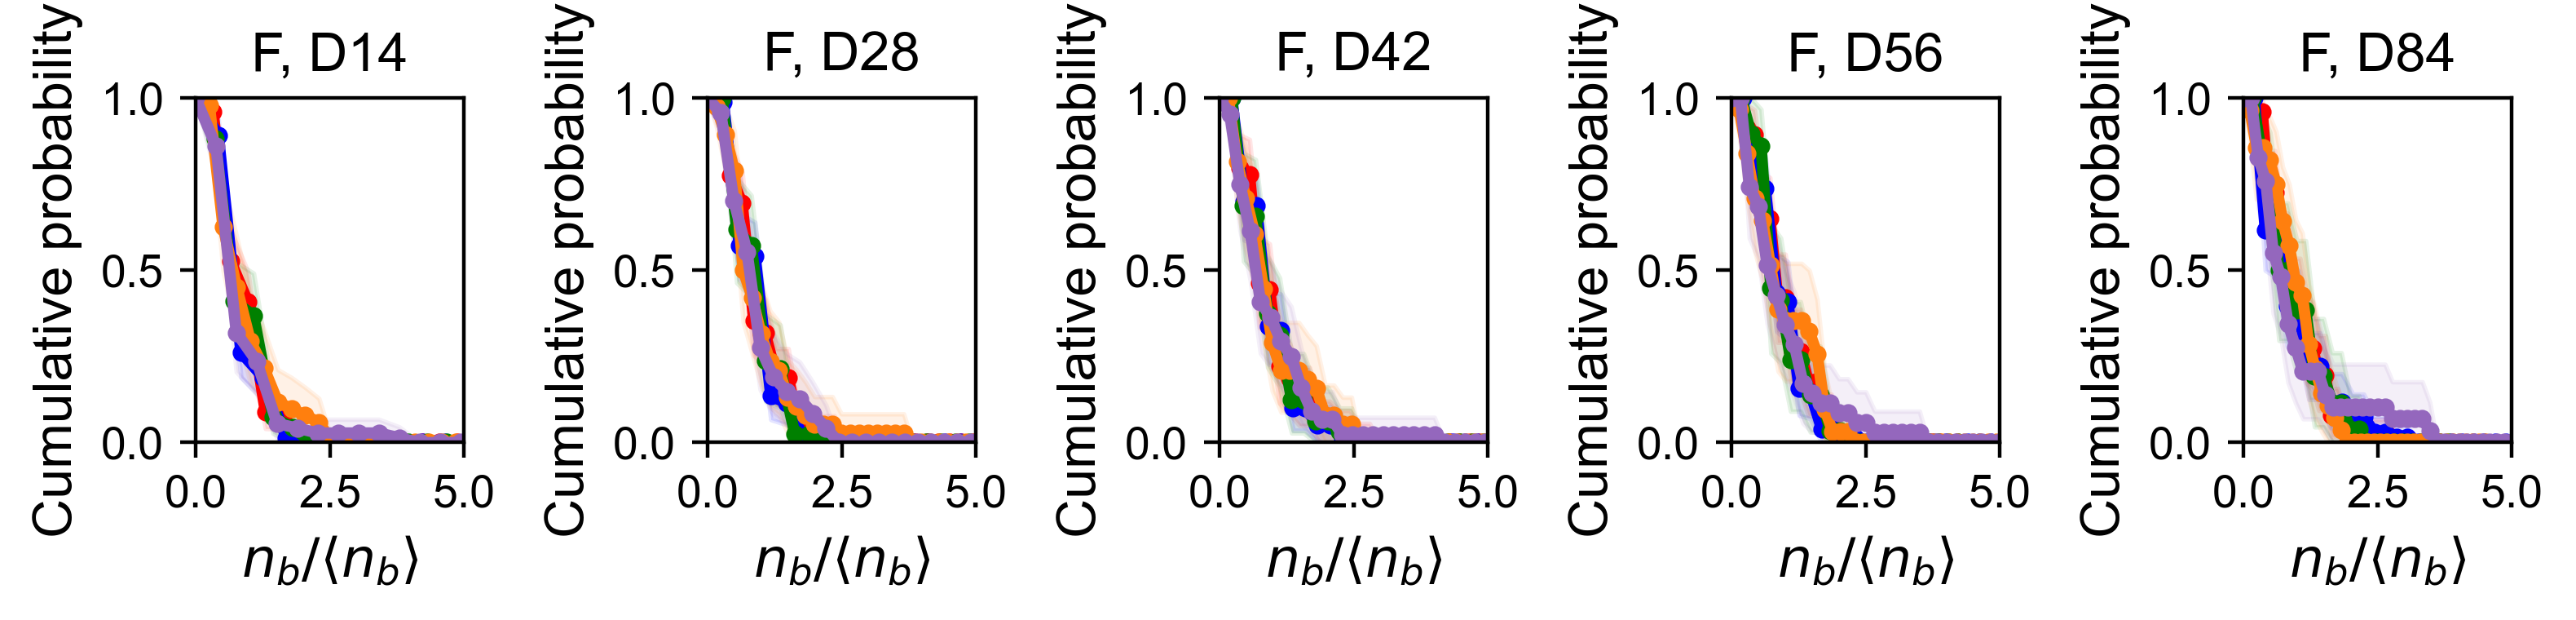

In [12]:
alpha = 1 - 0.95
fig, axs = plt.subplots(1, 5, figsize=(8, 2), dpi = 400)
xx = 0
times = list(exp_data['ctrTimeClonesize'])

subtimes = [1,3,4,5,6]

for mid in fmice[:]:
    exp_folder = '../../experiment/homeo/'
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    ccdf = clone_anal.bas_cdf()
    boot = clone_anal.bootpdf('bas_cdf', calc = None)
    l95 = np.quantile(boot, alpha/2, axis = 0)
    u95 = np.quantile(boot, 1 - alpha/2, axis = 0)

    for t in range(5):
        #xx = t // 4
        yy = t % 6
        tt = subtimes[t]
        axs[yy].plot(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], ccdf[tt,:].T, '-o', color = colm[mid], linewidth = 2.5, label = mid + f' ({clone_anal.nsur[t]})')
        axs[yy].fill_between(np.arange(ccdf.shape[1])/clone_anal.av_bas_cs[tt], l95[tt,:], u95[tt,:], color = colm[mid], alpha = 0.1)
        #if mid == mmice[-1]:
        x = np.linspace(0, 5, 100)
        #axs[yy].plot(x, np.exp(-(x-1/clone_anal.av_bas_cs[tt])), 'k-', label = r'$e^{-x}$')
        #    axs[yy].plot(x, np.exp(-x**2), 'k--', label = r'$e^{-x^2}$')
        #axs[yy].legend(loc = 'upper right')
        axs[yy].set_xlabel(r'$n_b/\langle n_b\rangle$')
        axs[yy].set_ylabel('Cumulative probability')
        #axs[yy].vlines([4,8,12,16], ymax = 0.4, ymin = 0, color = 'k', alpha = 0.15, linestyle = '--', label = '_nolegend_')
        #axs[yy].vlines([3,6,9,12,15], ymax = 0.4, ymin = 0, color = 'y', alpha = 0.15, linestyle = '--', label = '_nolegend_')            
        axs[yy].set_xlim([0, 5])
        axs[yy].set_yticks([0, 0.5, 1.0])
        #axs[yy].set_yticklabels(np.arange(0,1.1, 0.25), minor = True)
        axs[yy].set_ylim([0, 1])
        axs[yy].set_xticks([0, 2.5, 5.0])
        axs[yy].set_title(f'F, D{int(times[tt])}')
#plt.suptitle('Rescaled sizes, M, All clones', fontsize = 20)
plt.tight_layout()
plt.savefig(save_folder + 'rescaled_sizes_F.pdf')
plt.show()

Text(0, 0.5, 'Average basal clone size')

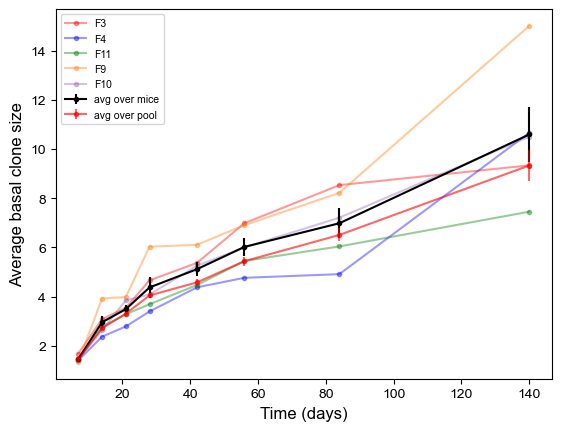

In [13]:
av = []
for mid in fmice:
    exp_data = load_object(exp_folder + 'data_ctr_' + mid + '.pkl')
    livesize = exp_data['livesize']
    av.append(clone_anal.av_bas_cs)

    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.plot(clone_anal.tvals, clone_anal.av_bas_cs, 'o-',  color = colm[mid], alpha = 0.4, label = mid)
plt.errorbar(clone_anal.tvals, np.mean(np.array(av),0), np.std(np.array(av),0)/np.sqrt(5), fmt = 'o-',  color = 'k', alpha = 1, label = 'avg over mice')

clone_anal = clones.xanalysis(livesize_F, verbose = False, tvals = exp_data['ctrTimeClonesize'])
plt.errorbar(clone_anal.tvals, clone_anal.av_bas_cs, clone_anal.se_bas_cs, fmt='o-',  color = 'r', alpha = 0.6, label = 'avg over pool')
plt.legend()
plt.xlabel('Time (days)')
plt.ylabel('Average basal clone size')